In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

In [2]:
%pip install seaborn

In [4]:
df=pd.read_csv("penguins_lter.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   studyName            344 non-null    str    
 1   Sample Number        344 non-null    int64  
 2   Species              344 non-null    str    
 3   Region               344 non-null    str    
 4   Island               344 non-null    str    
 5   Stage                344 non-null    str    
 6   Individual ID        344 non-null    str    
 7   Clutch Completion    344 non-null    str    
 8   Date Egg             344 non-null    str    
 9   Culmen Length (mm)   342 non-null    float64
 10  Culmen Depth (mm)    342 non-null    float64
 11  Flipper Length (mm)  342 non-null    float64
 12  Body Mass (g)        342 non-null    float64
 13  Sex                  334 non-null    str    
 14  Delta 15 N (o/oo)    330 non-null    float64
 15  Delta 13 C (o/oo)    331 non-null    float64
 16  C

In [5]:
import os
print(os.listdir())

['Untitled.ipynb', 'penguins_lter.csv', 'r.ipynb', 'Lorenz.ipynb', 'Mandelbrot.ipynb', 'sqlite.ipynb', 'cpp.ipynb', 'cpp-third-party-libs.ipynb', 'cpp-tiny-ray-tracer.ipynb', 'Intro.ipynb']


In [6]:
df.shape

(344, 17)

In [7]:
df.isnull().sum()

studyName                0
Sample Number            0
Species                  0
Region                   0
Island                   0
Stage                    0
Individual ID            0
Clutch Completion        0
Date Egg                 0
Culmen Length (mm)       2
Culmen Depth (mm)        2
Flipper Length (mm)      2
Body Mass (g)            2
Sex                     10
Delta 15 N (o/oo)       14
Delta 13 C (o/oo)       13
Comments               318
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
data = ["Culmen Length (mm)", "Culmen Depth (mm)", "Flipper Length (mm)", "Body Mass (g)"]
df[df[data].isnull().any(axis=1)]

,studyName,Sample Number,Species,Region,Island,Stage,Individual ID,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),Comments
3,PAL0708,4,Adelie Penguin (Pygoscelis adeliae),Anvers,Torgersen,"Adult, 1 Egg Stage",N2A2,Yes,11/16/07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Adult not sampled.
339,PAL0910,120,Gentoo penguin (Pygoscelis papua),Anvers,Biscoe,"Adult, 1 Egg Stage",N38A2,No,12/1/09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
df_clean = df.dropna(subset=data).copy()

In [11]:
df_clean.shape
df_clean[data].isnull().sum()

Culmen Length (mm)     0
Culmen Depth (mm)      0
Flipper Length (mm)    0
Body Mass (g)          0
dtype: int64

In [12]:
df_clean["Sex"].value_counts(dropna=False)

Sex
MALE      168
FEMALE    165
NaN         8
.           1
Name: count, dtype: int64

In [13]:
df_clean["Sex"] = df_clean["Sex"].replace(".", "Bilinmiyor")
df_clean["Sex"] = df_clean["Sex"].fillna("Bilinmiyor")

In [14]:
df_clean["Sex"].value_counts()

Sex
MALE          168
FEMALE        165
Bilinmiyor      9
Name: count, dtype: int64

In [15]:
df_clean[data].describe()

,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g)
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [16]:
df_clean["Species"].value_counts()

Species
Adelie Penguin (Pygoscelis adeliae)          151
Gentoo penguin (Pygoscelis papua)            123
Chinstrap penguin (Pygoscelis antarctica)     68
Name: count, dtype: int64

In [17]:
df_clean.groupby("Species")[data].mean()

,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g)
Species,,,,
Adelie Penguin (Pygoscelis adeliae),38.791391,18.346358,189.953642,3700.662252
Chinstrap penguin (Pygoscelis antarctica),48.833824,18.420588,195.823529,3733.088235
Gentoo penguin (Pygoscelis papua),47.504878,14.982114,217.186992,5076.016260


In [18]:
pd.crosstab(df_clean["Island"], df_clean["Species"])

Species,Adelie Penguin (Pygoscelis adeliae),Chinstrap penguin (Pygoscelis antarctica),Gentoo penguin (Pygoscelis papua)
Island,,,
Biscoe,44,0,123
Dream,56,68,0
Torgersen,51,0,0


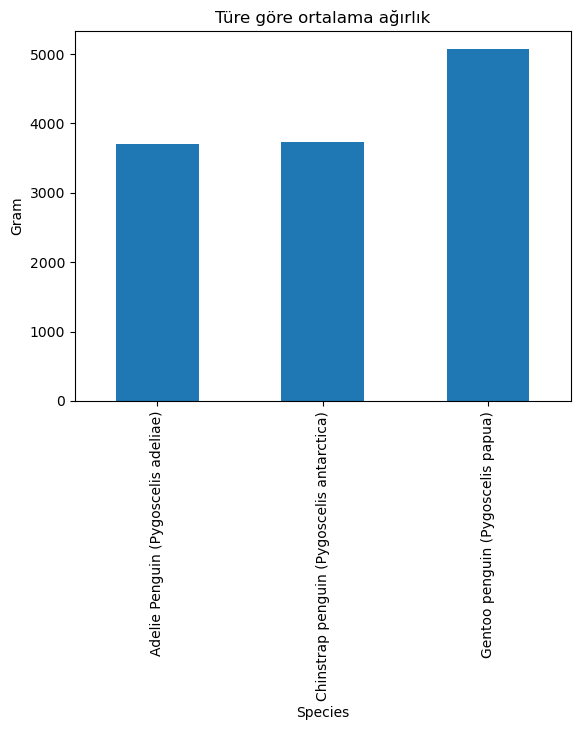

In [19]:
df_clean.groupby("Species")["Body Mass (g)"].mean().plot(kind="bar")
plt.title("Türe göre ortalama ağırlık")
plt.ylabel("Gram")
plt.show()

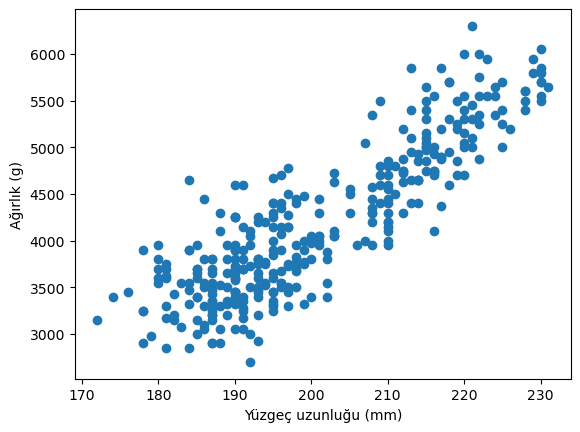

In [20]:
plt.scatter(df_clean["Flipper Length (mm)"], df_clean["Body Mass (g)"])
plt.xlabel("Yüzgeç uzunluğu (mm)")
plt.ylabel("Ağırlık (g)")
plt.show()

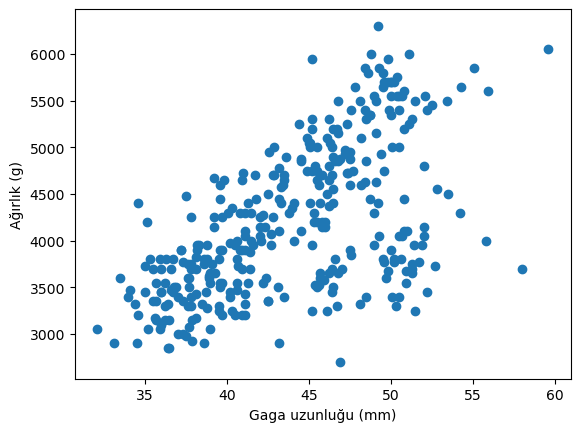

In [21]:
plt.scatter(df_clean["Culmen Length (mm)"], df_clean["Body Mass (g)"])
plt.xlabel("Gaga uzunluğu (mm)")
plt.ylabel("Ağırlık (g)")
plt.show()

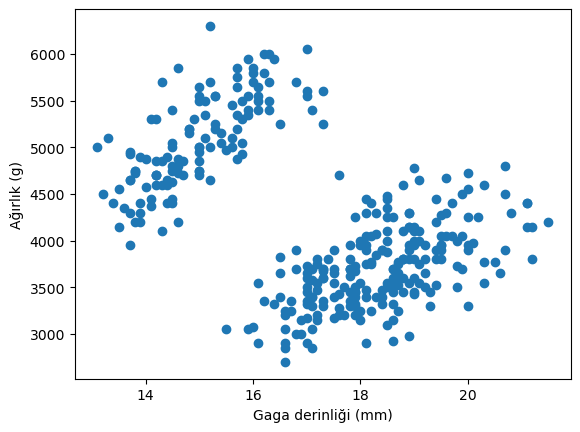

In [22]:
plt.scatter(df_clean["Culmen Depth (mm)"], df_clean["Body Mass (g)"])
plt.xlabel("Gaga derinliği (mm)")
plt.ylabel("Ağırlık (g)")
plt.show()

In [23]:
df_clean[data].corr()["Body Mass (g)"]

Culmen Length (mm)     0.595110
Culmen Depth (mm)     -0.471916
Flipper Length (mm)    0.871202
Body Mass (g)          1.000000
Name: Body Mass (g), dtype: float64

In [24]:
df_clean.groupby("Species")[data].mean()

,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g)
Species,,,,
Adelie Penguin (Pygoscelis adeliae),38.791391,18.346358,189.953642,3700.662252
Chinstrap penguin (Pygoscelis antarctica),48.833824,18.420588,195.823529,3733.088235
Gentoo penguin (Pygoscelis papua),47.504878,14.982114,217.186992,5076.016260


In [25]:
df_clean.groupby("Species")[data].mean()

,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g)
Species,,,,
Adelie Penguin (Pygoscelis adeliae),38.791391,18.346358,189.953642,3700.662252
Chinstrap penguin (Pygoscelis antarctica),48.833824,18.420588,195.823529,3733.088235
Gentoo penguin (Pygoscelis papua),47.504878,14.982114,217.186992,5076.016260


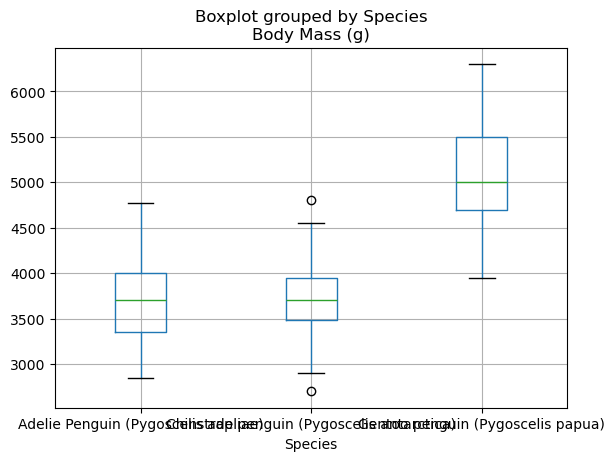

In [27]:
df_clean.boxplot(column="Body Mass (g)", by="Species")
plt.show()

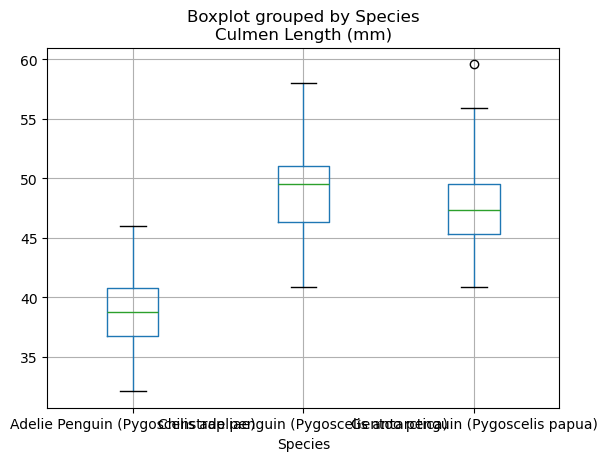

In [28]:
df_clean.boxplot(column="Culmen Length (mm)", by="Species")
plt.show()

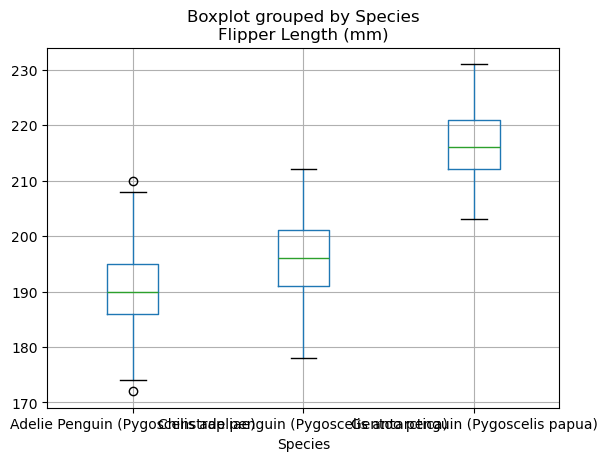

In [29]:
df_clean.boxplot(column="Flipper Length (mm)", by="Species")
plt.show()gentp

In [31]:
gentoo = df_clean[df_clean["Species"].str.contains("Gentoo")]
diger = df_clean[~df_clean["Species"].str.contains("Gentoo")]
print(gentoo.shape, diger.shape)

(123, 17) (219, 17)


In [32]:
for olcu in ["Flipper Length (mm)", "Body Mass (g)"]:
    kac = (diger[olcu] >= gentoo[olcu].min()).sum()
    print(olcu, kac)

Flipper Length (mm) 15
Body Mass (g) 65


In [33]:
df_clean["Sex"].value_counts(dropna=False)df_clean["Species"].unique()

Sex
MALE          168
FEMALE        165
Bilinmiyor      9
Name: count, dtype: int64

In [34]:
df_clean["Species"].unique()

<StringArray>
[      'Adelie Penguin (Pygoscelis adeliae)',
 'Chinstrap penguin (Pygoscelis antarctica)',
         'Gentoo penguin (Pygoscelis papua)']
Length: 3, dtype: str

In [35]:
df_clean["Species"] = df_clean["Species"].str.split().str[0]

In [36]:
df_clean["Species"].unique()

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

In [37]:
df_sql = df_clean.copy()
df_sql.columns = df_sql.columns.str.lower()
df_sql.columns = df_sql.columns.str.replace(" ", "_", regex=False)
df_sql.columns = df_sql.columns.str.replace("(", "", regex=False)
df_sql.columns = df_sql.columns.str.replace(")", "", regex=False)
df_sql.columns = df_sql.columns.str.replace("/", "", regex=False)
df_sql.to_csv("penguins_temiz.csv", index=False)
print(df_sql.columns.tolist())

['studyname', 'sample_number', 'species', 'region', 'island', 'stage', 'individual_id', 'clutch_completion', 'date_egg', 'culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'delta_15_n_ooo', 'delta_13_c_ooo', 'comments']
